# Fiche 3 — Corrélation de Pearson, de Spearman, et ce qu'elles ne disent pas

| | |
|---|---|
| 🎯 **Objectif** | Choisir le bon coefficient et l'utiliser pour repérer des indicateurs redondants |
| ⏱️ **Durée** | 45 min |
| 🧰 **Prérequis** | Fiche 2 (tableau pays × indicateurs) |
| 🔗 **Dans le projet** | Exercice partie 3, étape 1 |

> **L'idée clé.** Une corrélation mesure **à quel point deux variables évoluent ensemble**, sur une échelle de
> -1 à +1. Si deux indicateurs évoluent presque parfaitement ensemble, connaître l'un suffit : le second est
> **redondant**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from edstats import viz
from edstats.io import load_tables

viz.apply_style()
pd.set_option("display.max_colwidth", 70)

rng = np.random.default_rng(0)

## 1. Quatre situations pour tout comprendre

On fabrique des données dont on **connaît** la vraie relation, puis on regarde ce que disent les deux coefficients.

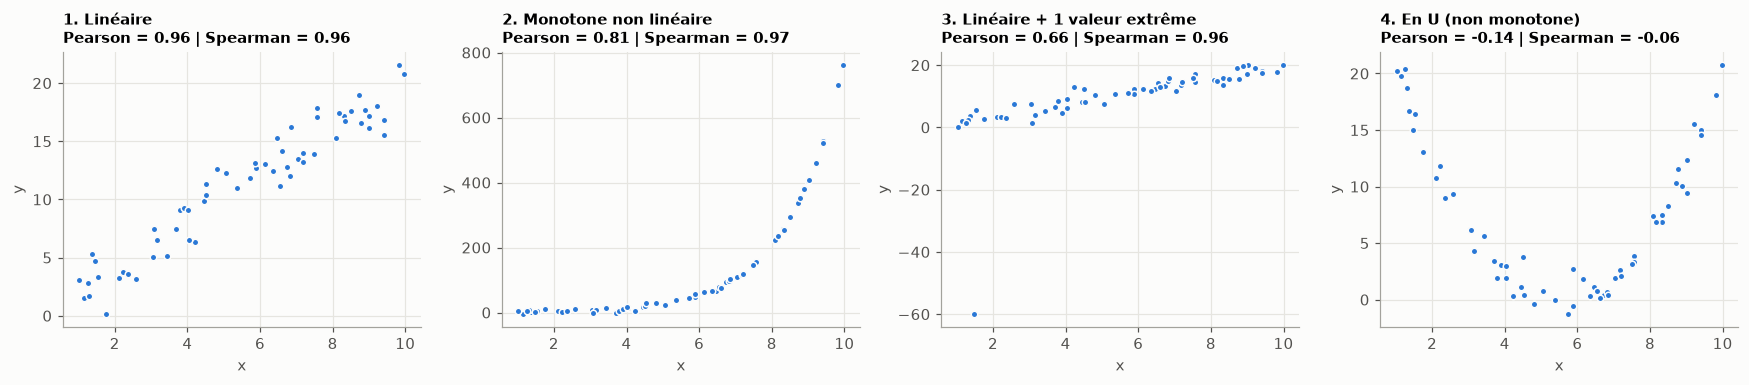

In [2]:
n = 60
x = rng.uniform(1, 10, n)
cas = {
    "1. Linéaire": 2 * x + rng.normal(0, 1.5, n),
    "2. Monotone non linéaire": np.exp(x / 1.5) + rng.normal(0, 5, n),
    "3. Linéaire + 1 valeur extrême": np.r_[2 * x[:-1] + rng.normal(0, 1.5, n - 1), -60],
    "4. En U (non monotone)": (x - 5.5) ** 2 + rng.normal(0, 1, n),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (titre, y) in zip(axes, cas.items()):
    pearson = pd.Series(x).corr(pd.Series(y))
    spearman = pd.Series(x).corr(pd.Series(y), method="spearman")
    ax.scatter(x, y, s=18, color=viz.BLUE, edgecolor=viz.SURFACE)
    ax.set_title(f"{titre}\nPearson = {pearson:.2f} | Spearman = {spearman:.2f}", fontsize=10)
    ax.set(xlabel="x", ylabel="y")
fig.tight_layout()
plt.show()

| Cas | Pearson | Spearman | Leçon |
|---|---|---|---|
| 1. Linéaire | 0,96 | 0,96 | les deux sont d'accord |
| 2. Monotone courbe | 0,81 | 0,97 | **Spearman** capte « quand x monte, y monte », même si ce n'est pas une droite |
| 3. Une valeur extrême | chute à 0,66 | reste à 0,96 | **un seul pays** (Chine, Inde…) suffit à fausser Pearson |
| 4. En U | ≈ -0,1 | ≈ -0,1 | **une corrélation nulle ne veut pas dire « aucun lien »** : elle veut dire « pas de lien monotone » |

**Comment ça marche ?** Spearman = Pearson calculé sur les **rangs** (1ᵉʳ, 2ᵉ, 3ᵉ…) au lieu des valeurs : un
pays 100 fois plus peuplé que le 2ᵉ n'est « que » 1ᵉʳ.

In [3]:
valeurs = pd.DataFrame({"x": [1, 2, 3, 4, 100], "y": [2, 4, 5, 9, 10]})
print("Pearson sur les valeurs :", round(valeurs.corr().iloc[0, 1], 3))
print("Pearson sur les rangs   :", round(valeurs.rank().corr().iloc[0, 1], 3))
print("Spearman sur les valeurs:", round(valeurs.corr(method="spearman").iloc[0, 1], 3), " ← identique")

Pearson sur les valeurs : 0.678
Pearson sur les rangs   : 1.0
Spearman sur les valeurs: 1.0  ← identique


## 2. Sur les vraies données

0.93 (Pearson)
0.79 (Spearman)


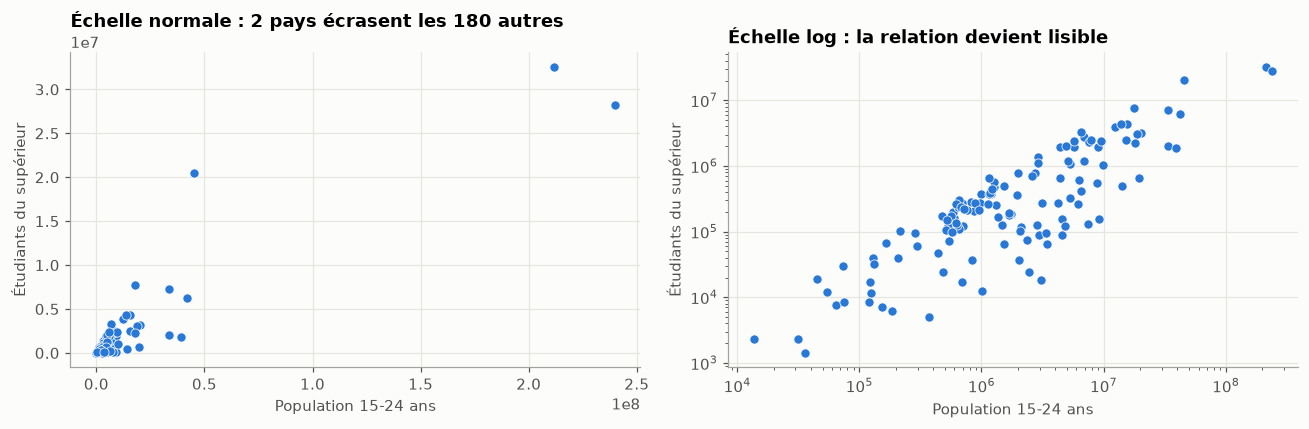

In [4]:
pays_indicateurs = pd.read_csv("../data/processed/pays_indicateurs.csv", index_col=0)
paire = ["Population 15-24 ans", "Étudiants du supérieur"]
print(pays_indicateurs[paire].corr(method="pearson").iloc[0, 1].round(2), "(Pearson)")
print(pays_indicateurs[paire].corr(method="spearman").iloc[0, 1].round(2), "(Spearman)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=pays_indicateurs, x=paire[0], y=paire[1], ax=axes[0], color=viz.BLUE)
axes[0].set_title("Échelle normale : 2 pays écrasent les 180 autres")
sns.scatterplot(data=pays_indicateurs, x=paire[0], y=paire[1], ax=axes[1], color=viz.BLUE)
axes[1].set(xscale="log", yscale="log", title="Échelle log : la relation devient lisible")
fig.tight_layout()
plt.show()

Ici, c'est l'inverse du cas 3 : Pearson (0,93) **dépasse** Spearman (0,79). Les géants (Inde, Chine) sont
extrêmes **sur les deux axes à la fois** et alignés : ils « tirent » la droite et gonflent Pearson. Une valeur extrême
peut donc aussi bien **gonfler** que **dégonfler** Pearson. Spearman, lui, regarde le classement des 180 pays et
donne une image plus fidèle de la relation pour un pays typique.

⚠️ **Piège : les valeurs manquantes.** `corr()` calcule chaque coefficient sur les pays où **les deux** valeurs
existent. Deux coefficients d'une même matrice peuvent donc porter sur des pays différents :

In [5]:
renseigne = pays_indicateurs.select_dtypes("number").notna().astype(int)
nb_pays_par_paire = renseigne.T @ renseigne  # produit matriciel : nb de pays où les DEUX colonnes sont remplies
nb_pays_par_paire.iloc[:4, :4]

,Population 15-24 ans,Population en âge du lycée,Population en âge universitaire,Population totale
Population 15-24 ans,181,178,167,180
Population en âge du lycée,178,195,179,193
Population en âge universitaire,167,179,180,180
Population totale,180,193,180,214


## 3. Corrélation n'est pas causalité

Le taux d'internet et le taux de scolarisation dans le supérieur sont très corrélés (ρ ≈ 0,8). Cela ne veut pas
dire qu'installer internet fait aller à l'université : les deux dépendent d'un **facteur commun**, la richesse du
pays. Pour la sélection d'indicateurs, cela n'a pas d'importance : on veut seulement savoir si l'un **renseigne**
sur l'autre.

## 4. De la corrélation à la redondance

In [6]:
from edstats.analysis import redundant_pairs

spearman = pays_indicateurs.select_dtypes("number").corr(method="spearman")
redundant_pairs(spearman, threshold=0.7).head(8).round(2)

,var_1,var_2,correlation
0,Population 15-24 ans,Population en âge universitaire,1.00
1,Population en âge universitaire,Population totale,0.99
2,Population en âge du lycée,Population en âge universitaire,0.99
3,Population 15-24 ans,Population en âge du lycée,0.99
4,Population 15-24 ans,Population totale,0.99
5,Population en âge du lycée,Population totale,0.98
6,Population totale,Élèves du secondaire,0.98
7,"PIB par habitant (PPA, $ int.)","RNB par habitant (Atlas, $ US)",0.98


Dans chaque paire, on garde **l'indicateur le plus utile pour le métier**. Ce n'est pas une décision statistique :
c'est pour cela que le corrigé parcourt les indicateurs par **ordre de priorité métier** (`select_non_redundant`).

### ✍️ À toi de jouer

Trace la heatmap de Spearman entre ces 4 indicateurs : internet, PIB par habitant (PPA), taux de scolarisation supérieure, part des 0-14 ans. Pourquoi la part des 0-14 ans est-elle **négativement** corrélée aux trois autres ?

In [7]:
# Ta réponse ici

<details>
<summary><b>💡 Voir une solution</b> (après avoir cherché !)</summary>

```python
cols = ["Utilisateurs d'internet (% population)", "PIB par habitant (PPA, $ int.)",
        "Taux brut de scolarisation supérieure (%)", "Part des 0-14 ans (%)"]
sns.heatmap(pays_indicateurs[cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap=viz.DIVERGING, vmin=-1, vmax=1)
```

Les pays riches ont fait leur transition démographique : moins d'enfants, donc une population plus âgée. Un coefficient négatif signale une relation **inverse**, pas une absence de relation. Pour la redondance, c'est la **valeur absolue** qui compte.
</details>

## ✅ À retenir

1. **Pearson** : relation linéaire, sensible aux valeurs extrêmes. **Spearman** : relation monotone, calculée sur les rangs, robuste.
2. Données très asymétriques (populations, PIB) : on préfère Spearman.
3. r ≈ 0 ne signifie pas « aucun lien » (cas du U).
4. `corr()` ignore les NaN **paire par paire** : vérifier sur combien de pays porte chaque coefficient.
5. Redondance = |r| élevé ; on tranche par le **métier**, pas par la statistique.
6. Corrélation ≠ causalité.